In [1]:
## Script for comparing model representations of neuro sentence sets
# Run with python 3.10 fMRI env
# James Fodor 2024

# load libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import itertools
import warnings
import pandas as pd

# load custom functions from library
import voxels_processing as vp

# set display options
np.set_printoptions(precision=3, threshold=7000, linewidth=200, suppress=True, floatmode='fixed')
sns.set()

# suppress annoying scipy warning
warnings.filterwarnings("ignore")

In [2]:
import importlib
importlib.reload(vp)

<module 'voxels_processing' from 'd:\\Code\\Python\\2023_07_Sentence_Meaning_in_the_Brain\\voxels_processing.py'>

### Load dataset and model similarities

In [146]:
## Load sentence set 

# set key parameters for loading data
dataset_name = 'Fodor2024-final108' # dataset name
repeats = [0,1,2,3] # stimulus repeats to include in analysis
num_sets = 6 # the number of sets of related sentences
timing = 'mid' # start, end, mid
corr_method = 'spearman'  # spearman or pearson correlation
similarity_type = 'cosine'  # options: 'cosine' or 'diemsim' or 'all'
controls_type = 1 # 1=sentence lengths only, 2=sentence lengths and minimum lengths, 3=visual cortex
accuracy_threshold = 0.73 # minimum accuracy on comprehension questions to include subjects (0.73 is default)
movement_threshold = 4.01 # maximum head movement (mean FD) to include subjects (4.01 is default)

# load sentence set into dictionary depending on type
sentences_dict = vp.load_set_of_sentences(dataset_name+'_sentences', pairs=False)
n = len(sentences_dict.keys()) # num sentences
print('\nloaded',dataset_name,'with',n,'sentences')
all_sentences = list(sentences_dict.values())

# define important subsets
all_sentences_indices = np.arange(len(all_sentences))
sent_pairs_all = list(itertools.combinations(all_sentences_indices, 2))
sent_pair_ids_all = np.arange(len(sent_pairs_all))
num_stimuli = all_sentences_indices.shape[0]
sent_pair_ids_diag = vp.get_pairs_in_diag(all_sentences_indices, num_sets=6)
sent_pair_ids_nondiags = [id for id in sent_pair_ids_all if id not in sent_pair_ids_diag]
sent_pair_ids_subset = np.array(sent_pair_ids_nondiags)[np.random.choice(len(sent_pair_ids_nondiags), size=int(len(sent_pair_ids_diag)/8), replace=False)] # take random subset of nondiags
sent_pair_ids_balanced = np.append(sent_pair_ids_subset,sent_pair_ids_diag)
print('Stimuli:',num_stimuli)
print('Pairs:',len(sent_pair_ids_all))


loaded Fodor2024-final108 with 108 sentences
Stimuli: 108
Pairs: 5778


In [147]:
## Compute length differences and min length for all sentence pairs and save if needed

# compute length differences for all sentence pairs
sent_length_diffs = []
sent_length_mins = []
sent_lengths = [len(x) for x in all_sentences]
for id_1,sent_1 in enumerate(all_sentences):
    sent_length_diff = []
    sent_length_min = []
    for id_2,sent_2 in enumerate(all_sentences):
        length_diff = np.abs(len(sent_1)-len(sent_2))
        length_min = np.min([len(sent_1),len(sent_2)])
        sent_length_diff.append(length_diff)
        sent_length_min.append(length_min)
    sent_length_diffs.append(sent_length_diff) 
    sent_length_mins.append(sent_length_min) 
sent_length_diffs_vector = np.array(sent_length_diffs)[np.triu_indices_from(np.array(sent_length_diffs), k=1)]

# save results if required
if (0):
    sims_path = 'Data-models/similarities/'
    np.savetxt(sims_path+dataset_name+'_neuro_diff_length.txt',sent_length_diffs_vector,fmt='%d')
    sent_length_mins_vector = np.array(sent_length_mins)[np.triu_indices_from(np.array(sent_length_mins), k=1)]
    np.savetxt(sims_path+dataset_name+'_neuro_min_length.txt',sent_length_mins_vector,fmt='%d')
    print('Length differences and min lengths computed and saved')

In [148]:
## Load fmri neuro data

# Load metadata for experimental subjects
subject_data_raw = np.loadtxt('Fodor2024-subject_data.txt', delimiter=';', dtype='str', encoding='utf-8', skiprows=1)
subject_data_dict = {sbj_data[0]:(sbj_data[1:]).astype('float') for sbj_data in subject_data_raw}
all_subjects = list(subject_data_dict.keys())
print('Loaded '+str(len(all_subjects))+' experimental subjects')

# Generate list of voxel sets for analysis
voxel_sets = []
for stability_level in ['0.04','0.07']:
    voxel_set_dict = vp.get_voxel_set_dict(stability_level)
    for voxel_set in voxel_set_dict:
        voxel_sets += voxel_set_dict[voxel_set]
        
voxel_sets = list(set(voxel_sets))
voxel_sets.sort()
default_voxel_set = 'LanROI-all-stable-0.07-norm'

# Specify voxel averaging and voxel subset options (for looping over later)
av_types = ['mean']
pair_subsets = ['all','diag']
other_parms = []
for av_type in av_types:
    for pair in pair_subsets:
        other_parms.append(av_type+'_'+pair)

# Collect subsets of sentences pairs for similarity analyses
similarity_subsets = {'all':sent_pair_ids_all, 'diag':sent_pair_ids_diag}
print('Voxel sets:',len(voxel_sets))

# Load neuro similarities
fmri_sims_base = 'Data-fmri/similarities/'
neuro_sims_storage = dict(zip(all_subjects, [{type:{} for type in av_types} for x in all_subjects])) # blank empty dictionary for storage
for sbj_id in list(subject_data_dict.keys()):
    for av_type in av_types:
        for voxel_set in voxel_sets:
            neuro_sims_path = fmri_sims_base+timing+'_3s/'+'sub-'+sbj_id+'-sims/'
            with open(neuro_sims_path+'sub-'+sbj_id+'_similarities-'+av_type+'-'+voxel_set+'.txt', encoding='latin-1') as file:
                neuro_sims_storage[sbj_id][av_type][voxel_set] = np.array([float(line.rstrip('\n')) for line in file])
                
# Specify which experimental subjects to include
included_subjects = [sbj_id for sbj_id in list(subject_data_dict.keys()) if subject_data_dict[sbj_id][0] >= accuracy_threshold and subject_data_dict[sbj_id][1] <= movement_threshold]
print('Including '+str(len(included_subjects))+' experimental subjects')

# Compute the average similarities over participants and store in dictionary
mean_subj_sims = {type:{} for type in av_types}
for av_type in av_types:
    for voxel_set in voxel_sets:
        voxelset_sims = [neuro_sims_storage[sbj_id][av_type][voxel_set] for sbj_id in included_subjects]
        mean_subj_sims[av_type][voxel_set] = np.mean(voxelset_sims, axis=0)
neuro_sims_storage['mean'] = mean_subj_sims
all_subjects = list(subject_data_dict.keys()) + ['mean'] # include mean subject data


Loaded 39 experimental subjects
Voxel sets: 32
Including 30 experimental subjects


In [149]:
## Load model similarities 

# Load model similarities
model_sims_base = 'Data-models/similarities/'
similarity_type = 'all'  # options: 'cosine' or 'diemsim' or 'all
model_sims_storage = vp.load_model_sims(model_sims_base, dataset_name, normalisation=True, sim_type=similarity_type)
print('Loaded '+str(len(model_sims_storage.keys()))+' computational models')

# Load some additional similarity sets
model_sims_storage['diag'] = [1 if pair in sent_pair_ids_diag else 0 for pair in sent_pair_ids_all]
model_sims_storage['hybrid-fix'] = 0.67*model_sims_storage['parse-GPT4_embed-conceptnet_weights-fixed_struct-low_verbnet']+0.33*model_sims_storage['conceptnet_mean_norml_cosine']
model_sims_storage['visual_sims'] = neuro_sims_storage['mean']['mean']['Glasser-primary_visual-stable-0.07-norm'] # visual similarities control
# model_sims_storage['lanROI'] = np.loadtxt('Data-analysis\\Fodor2024-final108_mid_mean_sims-LanROI-all-stable-0.07-norm.txt', dtype=float, encoding='utf-8')

# Load control variables
sent_length_diffs_vector = model_sims_storage['diff_length']
sent_length_mins_vector = model_sims_storage['min_length']
model_sims_storage['visual_sims'] = neuro_sims_storage['mean']['mean']['Glasser-primary_visual-stable-0.07-norm'] # visual similarities control
control_vars = vp.get_control_vars(controls_type, model_sims_storage)
print('Using '+str(controls_type)+' control variables')

Loaded 178 computational models
Using 1 control variables


### Plot RSA matrices

In [ ]:
## Select similarites to plot
   
# Regress out control variables from model sims
model_sims_resids,_ = vp.regress_out_controls(model_sims_storage, control_vars)

# Normalise similarities
model_sims_norml = vp.normalise_similarities(model_sims_resids, percentile=0)

# Convert model similarities to RSA matrices
RSA_matrices = {}
for model in model_sims_norml.keys():
    RSA_matrices[model] = vp.mask_based_utri2mat(model_sims_norml[model], num_stimuli)

# Define model subsets for plotting
models_subset = 2
similarity_type = 'cosine'

if models_subset==1: # main models for paper
    models_shortnames = ['conceptnet_mean_random_norml_'+similarity_type, 'conceptnet_mean_norml_'+similarity_type, 'openai_norml_'+similarity_type, 'conceptnet_weights-fixed_struct-low_verbnet', 'AMR_smatch', 'Prolific']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['Random', 'Mean-CN', 'OpenAI', 'VerbNet-CN', 'AMR-Smatch', 'Human']
    width_space = 0
    num_rows = 1
    num_cols = 6
    fig_width = 14.5
    save_name = 'rsmb'
    
elif models_subset==2: # all models
    similarity_type = 'all'
    models_shortnames = ['random', 'conceptnet_mean', 'conceptnet_mult_mod', 'conceptnet_conv_mod', 'glove6b', 'infersent', 
                         'ernie_12', 'llama3_32', 'amrbart_12', 
                         'universal', 'defsent_cls', 'sentbert_mpnet', 'openai', 'S3BERT_global', 
                         'benepar', 'CFG', 'AMR', 'conceptnet_weights-fixed_struct-low_verbnet', 
                         'GPT4_rated', 'Prolific_rated', 'diff', 'min', 'visual']
    model_names = ['Random-cs', 'Random-dm', 'CN-Mean-cs', 'CN-Mean-dm', 'CN-Mult-cs', 'CN-Mult-dm', 'CN-Conv-cs', 'CN-Conv-dm', 'Glove-cs', 'Glove-dm', 'Infersent-cs', 'Infersent-dm',
                   'Ernie-12-cs', 'Ernie-12-dm', 'Llama3-32-cs', 'Llama3-32-dm', 'AMRbart-12-cs', 'AMRbart-12-dm', 
                   'USE-cs', 'USE-dm', 'DefSent-cs', 'DefSent-dm', 'SentBERT-cs', 'SentBERT-dm', 'OpenAI-cs', 'OpenAI-dm', 'S3BERT', 
                   'Benepar-edit', 'Benepar-sub', 'CFG-edit', 'CFG-sub', 'AMR-CN', 'AMR-smatch', 'AMR-WLK', 'Verbnet-CN', 
                   'GPT4', 'Human', 'Length-sim', 'Length-min', 'Visual']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    width_space = -0.6
    num_rows = 6
    num_cols = 6
    fig_width = 17
    save_name = 'fullset'
    
elif models_subset==3: # hybrid versions
    models_shortnames = ['verbnet']
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['CN-equal-low', 'CN-equal-none', 'CN-fixed-low', 'CN-fixed-none', 'CN-STS3k-low', 'CN-STS3k-none', 'DS-equal-low', 'DS-equal-none', 'DS-fixed-low', 'DS-fixed-none', 'DS-STS3k-low', 'DS-STS3k-none']
    width_space = -0.3
    num_rows = 2
    num_cols = 3
    fig_width = 12
    save_name = 'hybrid'
    
elif models_subset==4: # ernie layers
    models_shortnames = ['conceptnet_mean_norml_'+similarity_type, 'conceptnet_weights-fixed_struct-low_verbnet'] + ['ernie_'+str(i)+'_norml_'+similarity_type for i in [0,4,8,12]]
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['Mn', 'VN'] + [''+str(i) for i in [0,4,8,12]]
    width_space = 0
    num_rows = 1
    num_cols = 6
    fig_width = 14.5
    save_name = 'ernie'
    
elif models_subset==5: # llama 3 layers
    models_shortnames = ['conceptnet_mean_norml_'+similarity_type, 'conceptnet_weights-fixed_struct-low_verbnet'] + ['llama3_'+str(i)+'_norml_'+similarity_type for i in [0,2,16,32]]
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['Mn', 'VN'] + [''+str(i) for i in [0,2,16,32]]
    width_space = 0
    num_rows = 1
    num_cols = 6
    fig_width = 14.5
    save_name = 'llama'
    
elif models_subset==6: # amrbart layers
    models_shortnames = ['conceptnet_mean_norml_'+similarity_type] + ['amrbart_'+str(i)+'_norml_'+similarity_type for i in [0,4,8,12]]
    included_models = vp.get_included_models(model_sims_storage, models_shortnames)
    model_names = ['Mn'] + [''+str(i) for i in [0,4,8,12]]
    width_space = 0
    num_rows = 1
    num_cols = 6
    fig_width = 14.5
    save_name = 'amrbart'
print('Number of included models:',len(included_models))
print('Number of model labels:',len(model_names))


Included models: ['conceptnet_mean_random_norml_cosine', 'conceptnet_mean_random_norml_diemsim', 'conceptnet_mean_norml_cosine', 'conceptnet_mean_norml_diemsim', 'conceptnet_mult_mod_norml_cosine', 'conceptnet_mult_mod_norml_diemsim', 'conceptnet_conv_mod_norml_cosine', 'conceptnet_conv_mod_norml_diemsim', 'glove6b_norml_cosine', 'glove6b_norml_diemsim', 'infersent_norml_cosine', 'infersent_norml_diemsim', 'ernie_12_norml_cosine', 'ernie_12_norml_diemsim', 'llama3_32_norml_cosine', 'llama3_32_norml_diemsim', 'amrbart_12_norml_cosine', 'amrbart_12_norml_diemsim', 'universal_norml_cosine', 'universal_norml_diemsim', 'defsent_cls_norml_cosine', 'defsent_cls_norml_diemsim', 'sentbert_mpnet_norml_cosine', 'sentbert_mpnet_norml_diemsim', 'openai_norml_cosine', 'openai_norml_diemsim', 'S3BERT_global', 'benepar_edit', 'benepar_subtree', 'CFG_edit', 'CFG_subtree', 'AMR_hybrid', 'AMR_smatch', 'AMR_WLK', 'parse-GPT4_embed-conceptnet_weights-fixed_struct-low_verbnet', 'GPT4_rated', 'Prolific_rated

In [154]:
## Generate RSA plots for all models and neuro data

# Define plot
fig = plt.figure(figsize=(fig_width,5*num_rows), dpi=600)
fig.subplots_adjust(wspace=width_space, hspace=0.2)
sns.set(font_scale=0.9)

# Generate subplots
for idx,model in enumerate(included_models):
    plot_num = (2*num_rows,num_cols,idx+1)
    show_colorbar=False
    # if idx==len(included_models)-1: # show for final model
    #     show_colorbar=True
    model_name = model_names[idx]
    vp.add_heatmap_subplot(fig, plot_num, RSA_matrices[model], model_name, sbj_id='', subplot='', min=np.min(model_sims_norml[model]), max=np.max(model_sims_norml[model]), colorbar=show_colorbar)
plt.savefig('Figures\\'+dataset_name+'_models_RSAs-'+save_name+'_controls-'+str(controls_type)+'.png', bbox_inches='tight')
plt.show()

Fodor2024-final108: 5778 pairs


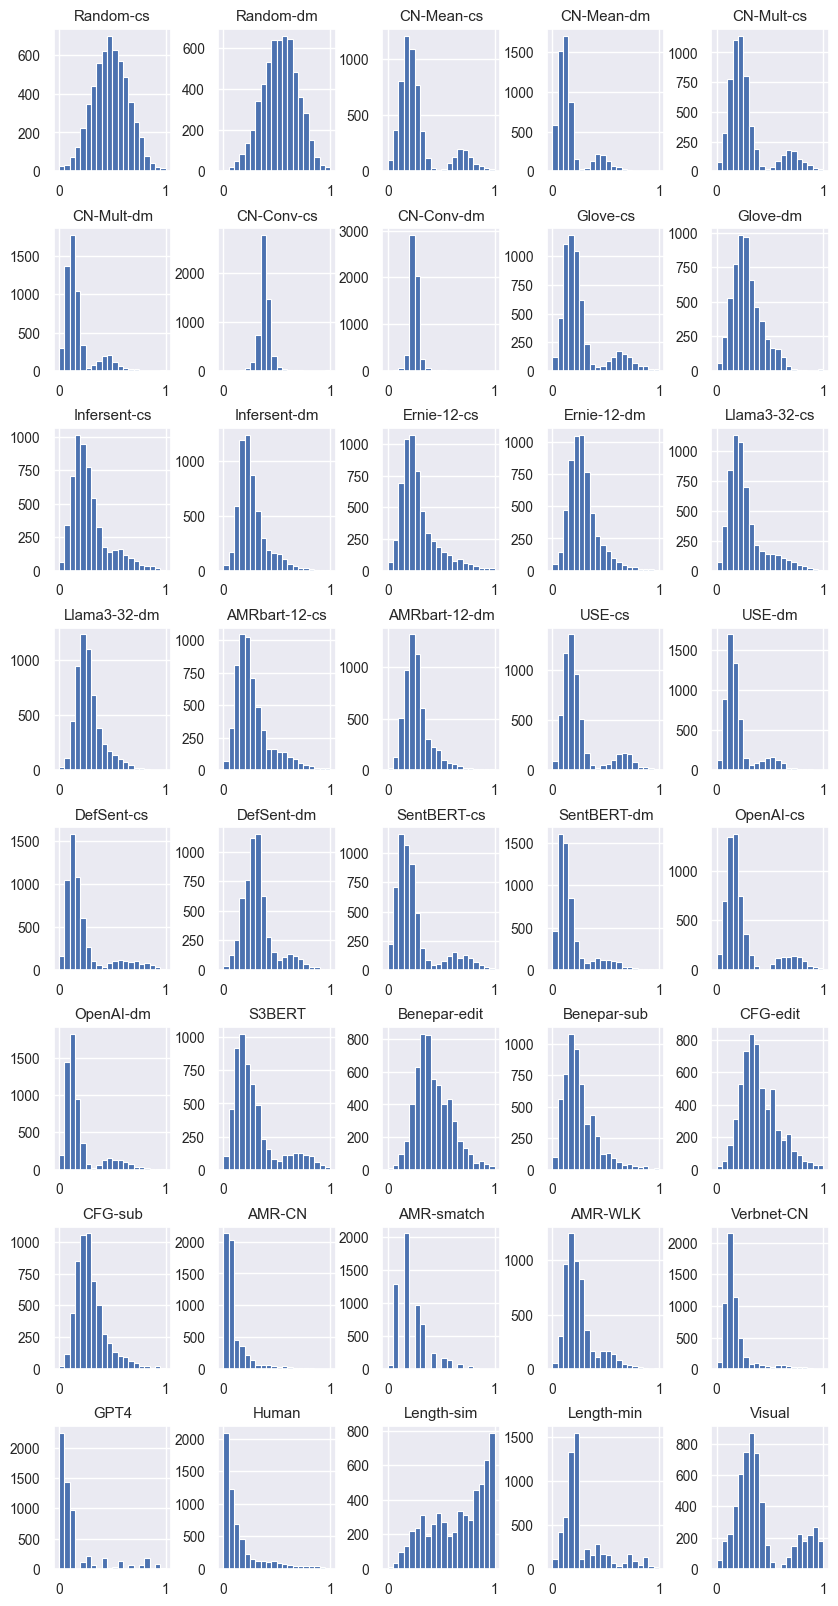

In [28]:
# Product histograms for each model
included_pairs = sent_pair_ids_all # sent_pair_ids_diag, sent_pair_ids_all
print(dataset_name+': '+str(len(included_pairs))+' pairs')

fig = plt.figure(figsize=(10,20), dpi=100)
fig.subplots_adjust(wspace=0.4, hspace=0.4)
sns.set(font_scale=0.9)
for idx,model in enumerate(included_models):
    plot_num = [8,5,idx+1]
    fig_axis = fig.add_subplot(*plot_num)
    plt.title(model_names[idx])
    plt.hist(model_sims_norml[model][included_pairs], linewidth=0.8, bins=np.arange(0,1.05,step=0.05))

### Compute and Plot Correlations

In [29]:
# Load data
included_pairs = sent_pair_ids_all # sent_pair_ids_diag, sent_pair_ids_all
included_sims_data = np.array([model_sims_norml[model][included_pairs] for model in included_models])
df_data = pd.DataFrame(included_sims_data.T)

# Print correlation matrix
df_corr = df_data.corr(method='spearman')
df_corr.columns = model_names
df_corr.index = model_names
print(dataset_name+': '+str(len(included_pairs))+' pairs')
df_corr.style.background_gradient(cmap='coolwarm').format(precision=2).set_table_styles(
    [{'selector': 'th.col_heading',
      'props': [
        ('max-width', '30px'),
        ('white-space', 'normal')
       ]
     },
     {'selector': 'th.row_heading',
        'props': [
            ("min-width", "100px"),
            ("max-width", "100px"),
            ("white-space", "nowrap"),
            ("overflow", "hidden"),
            ("text-overflow", "ellipsis"),
        ],
     }
    ])

Fodor2024-final108: 5778 pairs


,Random-cs,Random-dm,CN-Mean-cs,CN-Mean-dm,CN-Mult-cs,CN-Mult-dm,CN-Conv-cs,CN-Conv-dm,Glove-cs,Glove-dm,Infersent-cs,Infersent-dm,Ernie-12-cs,Ernie-12-dm,Llama3-32-cs,Llama3-32-dm,AMRbart-12-cs,AMRbart-12-dm,USE-cs,USE-dm,DefSent-cs,DefSent-dm,SentBERT-cs,SentBERT-dm,OpenAI-cs,OpenAI-dm,S3BERT,Benepar-edit,Benepar-sub,CFG-edit,CFG-sub,AMR-CN,AMR-smatch,AMR-WLK,Verbnet-CN,GPT4,Human,Length-sim,Length-min,Visual
Random-cs,1.00,0.59,0.02,0.02,0.02,0.02,-0.01,-0.01,0.02,0.02,0.02,0.02,0.03,0.02,0.01,0.01,0.03,0.02,0.02,0.02,-0.01,0.00,0.00,0.01,0.01,0.02,0.01,0.01,0.02,0.01,0.02,0.01,0.03,0.02,0.02,0.01,0.01,0.01,0.01,0.00
Random-dm,0.59,1.00,0.02,0.05,0.02,0.05,0.00,-0.03,0.02,0.06,0.02,0.01,0.02,-0.02,0.02,0.01,0.02,-0.01,0.03,0.05,0.00,-0.05,0.01,0.01,0.02,0.02,0.01,-0.02,-0.01,-0.01,-0.00,0.01,0.04,0.04,0.02,0.01,-0.00,-0.01,-0.03,-0.06
CN-Mean-cs,0.02,0.02,1.00,0.92,0.95,0.91,0.07,0.04,0.87,0.65,0.80,0.69,0.64,0.47,0.66,0.55,0.68,0.53,0.75,0.66,0.72,0.48,0.78,0.68,0.81,0.73,0.66,0.11,0.39,0.11,0.44,0.41,0.40,0.57,0.70,0.59,0.51,0.04,0.09,0.11
CN-Mean-dm,0.02,0.05,0.92,1.00,0.91,0.97,0.07,0.03,0.82,0.70,0.80,0.78,0.64,0.57,0.64,0.59,0.67,0.56,0.72,0.70,0.70,0.47,0.76,0.75,0.78,0.79,0.75,0.11,0.38,0.11,0.43,0.46,0.49,0.68,0.72,0.68,0.54,0.02,0.09,0.14
CN-Mult-cs,0.02,0.02,0.95,0.91,1.00,0.94,0.05,0.04,0.84,0.55,0.84,0.76,0.68,0.57,0.68,0.59,0.74,0.64,0.76,0.72,0.71,0.51,0.77,0.72,0.80,0.76,0.71,0.25,0.50,0.24,0.51,0.49,0.42,0.64,0.69,0.67,0.55,0.18,0.03,0.09
CN-Mult-dm,0.02,0.05,0.91,0.97,0.94,1.00,0.07,0.03,0.81,0.68,0.83,0.79,0.67,0.57,0.65,0.59,0.71,0.59,0.73,0.69,0.68,0.44,0.75,0.71,0.77,0.76,0.72,0.15,0.41,0.15,0.46,0.44,0.47,0.65,0.72,0.66,0.53,0.12,0.11,0.16
CN-Conv-cs,-0.01,0.00,0.07,0.07,0.05,0.07,1.00,0.94,0.08,0.13,0.06,0.06,0.05,0.03,0.04,0.03,0.05,0.01,0.03,0.01,0.06,0.05,0.05,0.03,0.05,0.03,0.03,-0.07,-0.05,-0.07,-0.02,-0.01,0.05,0.05,0.07,0.02,0.02,-0.01,0.10,0.08
CN-Conv-dm,-0.01,-0.03,0.04,0.03,0.04,0.03,0.94,1.00,0.04,0.01,0.03,0.03,0.04,0.03,0.03,0.03,0.03,0.02,0.01,0.00,0.03,0.03,0.02,0.02,0.03,0.02,0.02,0.02,0.03,0.02,0.02,0.02,-0.01,0.02,0.03,0.02,0.01,0.04,-0.02,-0.02
Glove-cs,0.02,0.02,0.87,0.82,0.84,0.81,0.08,0.04,1.00,0.70,0.77,0.66,0.63,0.48,0.68,0.57,0.64,0.50,0.65,0.58,0.66,0.46,0.69,0.58,0.74,0.67,0.57,0.09,0.38,0.09,0.40,0.39,0.39,0.61,0.61,0.56,0.49,0.03,0.07,0.11
Glove-dm,0.02,0.06,0.65,0.70,0.55,0.68,0.13,0.01,0.70,1.00,0.57,0.54,0.50,0.34,0.53,0.47,0.50,0.31,0.51,0.38,0.50,0.35,0.53,0.44,0.55,0.49,0.43,-0.30,0.05,-0.26,0.18,0.16,0.48,0.47,0.55,0.40,0.40,-0.18,0.39,0.38


In [ ]:
# Compute partial correlations between models
from pingouin import partial_corr
all_data = np.array([model_sims_norml['Human'][included_pairs], model_sims_norml['OpenAI-cs'][included_pairs]])
col_names = ['human', 'model']
control_vars = [model_sims_norml['length_diff'][included_pairs]]
control_var_names = []
for idx,control_var in enumerate(control_vars): # store control variables
    all_data = np.vstack((all_data, control_var))
    control_var_names.append('control_'+str(idx))
    col_names.append('control_'+str(idx))
df = pd.DataFrame(np.array(all_data), index=col_names).T
        
partial_corr(data=df, x='human', y='model', covar=control_var_names, method='spearman').values[0]